In [51]:
# Install required packages
!pip install -q qiskit qiskit-aer qiskit-ibm-runtime matplotlib pylatexenc
!pip install -q qiskit-algorithms

# Imports
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from qiskit.primitives import StatevectorSampler
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import depolarizing_error
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.state_fidelities import ComputeUncompute
from qiskit.quantum_info import (
    Statevector,
    DensityMatrix,
    state_fidelity
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 6.7 MB/s eta 0:00:00


In [52]:
from qiskit import QuantumCircuit

def create_bell_state(state):

    qc = QuantumCircuit(2)

    qc.h(0)
    qc.cx(0, 1)

    if state == "phi-":
        qc.z(0)

    elif state == "psi+":
        qc.x(1)

    elif state == "psi-":
        qc.x(1)
        qc.z(0)

    qc.measure_all()

    return qc

In [53]:
# ==========================================
# Create Bell State without measurements
# ==========================================

def create_bell_state_no_measure(state):

    qc = QuantumCircuit(2)

    qc.h(0)
    qc.cx(0, 1)

    if state == "phi-":
        qc.z(0)

    elif state == "psi+":
        qc.x(1)

    elif state == "psi-":
        qc.x(1)
        qc.z(0)

    return qc

In [54]:
# ==========================================
# Step 3 - Choose Bell State
# ==========================================

print("========== Bell State Explorer ==========")
print("1 -> Phi+")
print("2 -> Phi-")
print("3 -> Psi+")
print("4 -> Psi-")

choice = input("Choose a Bell State: ")

bell_dict = {
    "1": "phi+",
    "2": "phi-",
    "3": "psi+",
    "4": "psi-"
}

state = bell_dict.get(choice)

if state is None:
    print("Invalid choice!")
else:
    print(f"You selected: {state}")

========== Bell State Explorer ==========
1 -> Phi+
2 -> Phi-
3 -> Psi+
4 -> Psi-
Choose a Bell State: 3
You selected: psi+


Ideal Counts:
{'01': 481, '10': 543}


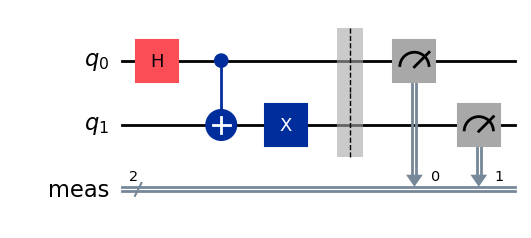

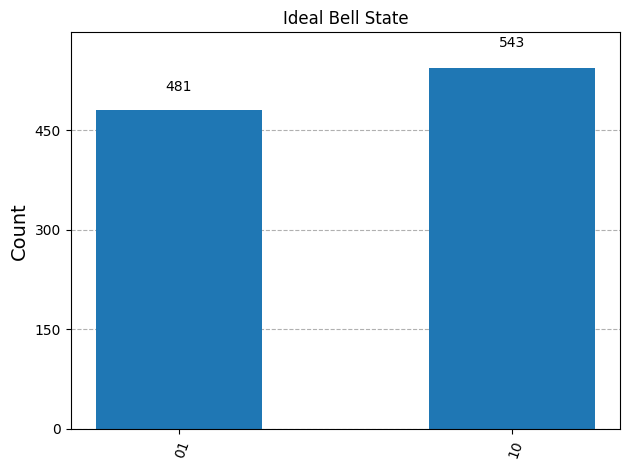

In [55]:
# ==========================================
# Step 4 - Ideal Simulation
# ==========================================

# Create the selected Bell State
qc = create_bell_state(state)

# Create the sampler
sampler = StatevectorSampler()

# Execute the circuit
job = sampler.run([qc])

# Get the result
result = job.result()

# Extract measurement counts
ideal_counts = result[0].data.meas.get_counts()

print("Ideal Counts:")
print(ideal_counts)

# Draw the circuit
display(qc.draw("mpl"))

# Plot histogram
fig = plot_histogram(
    ideal_counts,
    title="Ideal Bell State"
)

display(fig)

In [56]:
# ==========================================
# Step 5 - Noisy Simulation
# ==========================================

# Create the Noise Simulator
simulator = AerSimulator(
    noise_model=noise_model
)

# Transpile the circuit for the simulator
qc_noisy = transpile(
    qc,
    simulator
)

# Execute the noisy circuit
result = simulator.run(
    qc_noisy,
    shots=1024
).result()

# Extract counts
noisy_counts = result.get_counts()

print("Noisy Counts:")
print(noisy_counts)


Noisy Counts:
{'11': 30, '01': 450, '00': 21, '10': 523}


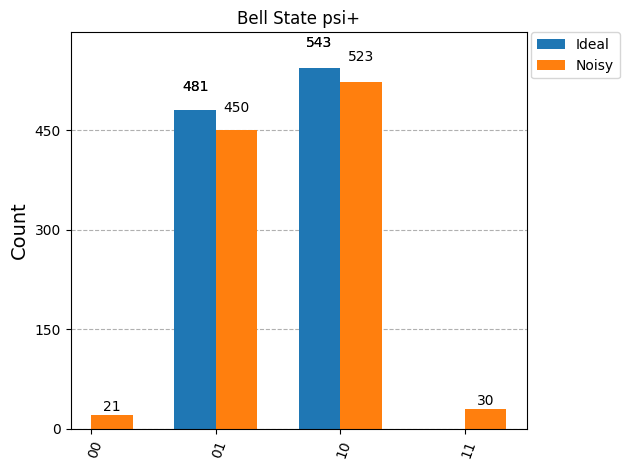

In [57]:
# ==========================================
# Step 6 - Compare Results
# ==========================================

fig = plot_histogram(
    [ideal_counts, noisy_counts],
    legend=["Ideal", "Noisy"],
    title=f"Bell State {state}"
)

display(fig)

In [58]:
# ==========================================
# Step 7 - Fidelity

ideal_circuit = create_bell_state_no_measure(state)

ideal_state = Statevector.from_instruction(
    ideal_circuit
)

ideal_circuit.save_density_matrix()

simulator = AerSimulator(
    noise_model=noise_model
)

result = simulator.run(
    transpile(
        ideal_circuit,
        simulator
    )
).result()

noisy_state = DensityMatrix(
    result.data(0)["density_matrix"]
)

fidelity = state_fidelity(
    ideal_state,
    noisy_state
)

print("Fidelity =", fidelity)

Fidelity = 0.9043124999999999


In [59]:
# ==========================================
# Compute-Uncompute Fidelity
# ==========================================

# ------------------------------------------
# Create the IDEAL Bell State
# ------------------------------------------

ideal = QuantumCircuit(2)

ideal.h(0)
ideal.cx(0, 1)

# ------------------------------------------
# Create the TEST Bell State
# ------------------------------------------

test = QuantumCircuit(2)

test.h(0)
test.cx(0, 1)

# Simulate an error
test.x(1)

# ------------------------------------------
# Compute Fidelity
# ------------------------------------------

sampler = StatevectorSampler()

compute_uncompute = ComputeUncompute(sampler)

job = compute_uncompute.run([ideal], [test])

result = job.result()

print("Compute-Uncompute Fidelity =", result.fidelities[0])

Compute-Uncompute Fidelity = 0


In [60]:
# ==========================================
# Step 9 - Summary
# ==========================================

print("\n========== Project Summary ==========\n")

print(f"Bell State : {state}")

print()

print("Ideal Counts:")
print(ideal_counts)

print()

print("Noisy Counts:")
print(noisy_counts)

print()

print(f"Fidelity : {fidelity:.4f}")

print("\n=====================================")


========== Project Summary ==========

Bell State : psi+

Ideal Counts:
{'01': 481, '10': 543}

Noisy Counts:
{'11': 30, '01': 450, '00': 21, '10': 523}

Fidelity : 0.9043

